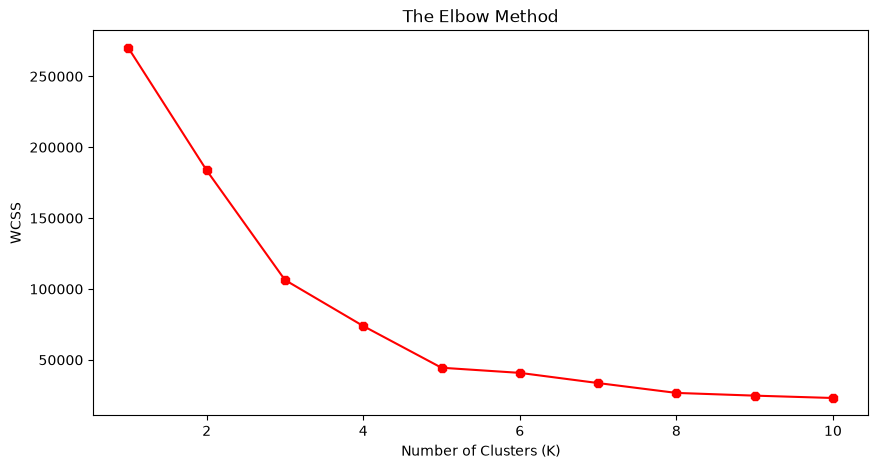

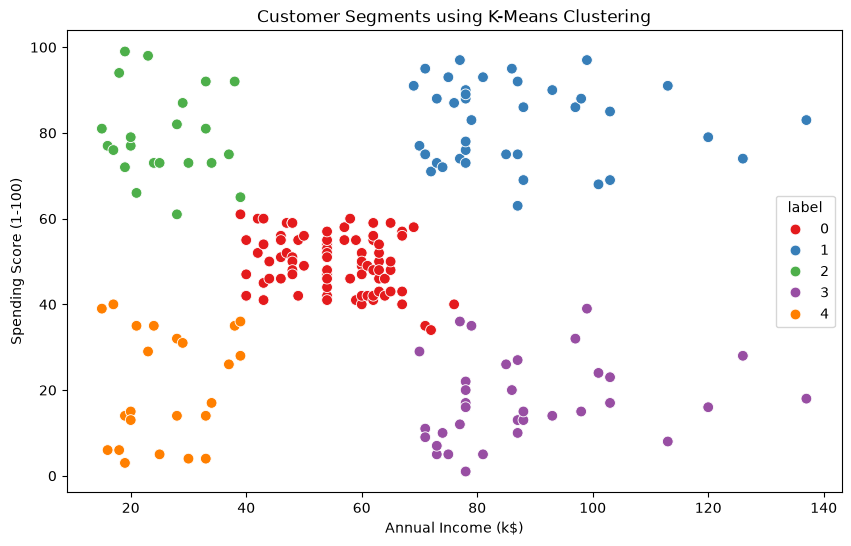

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 1. Read the dataset[cite: 100]
df = pd.read_csv('Mall_Customers.csv')

# 2. Select features (Annual Income and Spending Score)[cite: 104]
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# 3. Calculate WCSS for the Elbow Method[cite: 105]
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve[cite: 105]
plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker='8', color='red')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.show()

# 4. Apply K-Means with optimal clusters (K=5 based on the elbow graph)[cite: 106]
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
df['label'] = kmeans.fit_predict(X)

# 5. Visualize the Clusters[cite: 107]
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', hue='label', palette='Set1', data=df, s=60)
plt.title('Customer Segments using K-Means Clustering')
plt.show()